# Influence du ratio d'anomalies LLM et du paramètre alpha

Ce notebook compare **SERAG** (`alpha = 0.5`) et **LoGNet** sur les protocoles chronological et pooled construits à partir des mêmes 30 snapshots ICEWS18. Les ratios d'anomalies du train sont 1 %, 2,5 %, 5 %, 10 % et 20 %. La validation et le test restent fixés à 10 %. Une seconde analyse étudie SERAG pour `alpha` compris entre 0 (branche relationnelle seule) et 1 (branche sémantique seule), à un ratio fixé à 10 %.

Chaque résultat est calculé sur les seeds 41 à 45 et présenté sous la forme **moyenne ± écart-type**. Les checkpoints de SERAG et LoGNet sont sélectionnés sur l'AUPRC de validation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    from IPython.display import Markdown, display
except ImportError:  # Permet aussi l'exécution comme script Python.
    Markdown = str
    display = print
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

REPO_DIR = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "outputs").is_dir() and (path / "src").is_dir()
)
OUTPUTS_DIR = REPO_DIR / "outputs"
RATIOS = (0.01, 0.025, 0.05, 0.1, 0.2)
SEEDS = (41, 42, 43, 44, 45)
PROTOCOLS = ("chronological_30_llm", "pooled_30_llm")
MODELS = ("lognet", "serag")

def protocol_label(protocol: str) -> str:
    return "Chronological" if protocol == "chronological_30_llm" else "Pooled"

REPO_DIR

dyld[61629]: Library not loaded: /opt/local/lib/libiconv.2.dylib
  Referenced from: <2D65893A-0D90-3CA4-8F75-B7310306D9B3> /opt/local/bin/fc-list
  Reason: tried: '/opt/local/lib/libiconv.2.dylib' (mach-o file, but is an incompatible architecture (have 'x86_64', need 'arm64e, arm64e.v1, arm64, arm64')), '/System/Volumes/Preboot/Cryptexes/OS/opt/local/lib/libiconv.2.dylib' (no such file), '/opt/local/lib/libiconv.2.dylib' (mach-o file, but is an incompatible architecture (have 'x86_64', need 'arm64e, arm64e.v1, arm64, arm64'))


PosixPath('/Users/lmoncla/git/github.com/lmoncla/knowledge-graph-anomaly-detection')

## Influence du paramètre alpha

Cette ablation utilise un ratio de 10 % dans les trois partitions. `alpha = 0` correspond à la branche relationnelle seule et `alpha = 1` à la branche sémantique seule. Les valeurs intermédiaires combinent les deux logits calibrés.

In [2]:
ALPHAS = (0.0, 0.25, 0.5, 0.75, 0.85, 0.95, 1.0)
ALPHA_LABELS = {alpha: f"{alpha:g}" for alpha in ALPHAS}
alpha_frames = []
for protocol in PROTOCOLS:
    for alpha in ALPHAS:
        if protocol == "chronological_30_llm":
            path = (
                OUTPUTS_DIR / "cpu_llm_chronological_30" / "serag" / protocol
                / "ratio_0.1" / f"alpha_{alpha:g}" / "summary_by_seed.csv"
            )
        else:
            path = (
                OUTPUTS_DIR / "cpu_llm_alpha_sweep" / protocol / "ratio_0.1"
                / f"alpha_{alpha:g}" / "summary_by_seed.csv"
            )
        if not path.is_file():
            raise FileNotFoundError(path)
        frame = pd.read_csv(path)
        frame["protocol"] = protocol
        frame["alpha"] = alpha
        alpha_frames.append(frame)

alpha_results = pd.concat(alpha_frames, ignore_index=True)
alpha_completeness = (
    alpha_results.groupby(["protocol", "alpha"], as_index=False)
    .agg(n_seeds=("seed", "nunique"), n_ok=("status", lambda values: values.eq("ok").sum()))
)
assert len(alpha_results) == len(PROTOCOLS) * len(ALPHAS) * len(SEEDS)
assert alpha_completeness[["n_seeds", "n_ok"]].eq(len(SEEDS)).all().all()

def format_french(value: float) -> str:
    return f"{value:.3f}".replace(".", ",")

alpha_metrics = {"auc_test": "AUROC", "auprc_test": "AUPRC", "f1_test": "F1"}
alpha_aggregated = (
    alpha_results.groupby(["protocol", "alpha"])[list(alpha_metrics)]
    .agg(["mean", "std"])
)

def alpha_results_table(protocol: str) -> pd.DataFrame:
    rows = []
    for metric, label in alpha_metrics.items():
        row = {}
        for alpha in ALPHAS:
            values = alpha_aggregated.loc[(protocol, alpha), metric]
            row[ALPHA_LABELS[alpha]] = f"{format_french(values['mean'])} ± {format_french(values['std'])}"
        rows.append(row)
    return pd.DataFrame(rows, index=pd.Index(alpha_metrics.values(), name="Métrique"))

for protocol in PROTOCOLS:
    label = protocol_label(protocol)
    display(alpha_results_table(protocol).style.set_caption(f"{label} — moyenne ± écart-type sur cinq seeds"))

alpha_selection = []
for protocol in PROTOCOLS:
    validation = alpha_results[alpha_results.protocol.eq(protocol)].groupby("alpha")["auprc_validation"].mean()
    selected_alpha = float(validation.idxmax())
    selected = alpha_results[alpha_results.protocol.eq(protocol) & alpha_results.alpha.eq(selected_alpha)]
    alpha_selection.append({
        "Protocole": protocol_label(protocol),
        "Alpha sélectionné sur validation": ALPHA_LABELS[selected_alpha],
        "AUPRC validation": f"{format_french(selected.auprc_validation.mean())} ± {format_french(selected.auprc_validation.std())}",
        "AUPRC test": f"{format_french(selected.auprc_test.mean())} ± {format_french(selected.auprc_test.std())}",
    })
display(pd.DataFrame(alpha_selection).style.hide(axis="index"))

,0,0.25,0.5,0.75,0.85,0.95,1
Métrique,,,,,,,
AUROC,"0,672 ± 0,003","0,705 ± 0,004","0,737 ± 0,003","0,750 ± 0,003","0,745 ± 0,004","0,740 ± 0,005","0,737 ± 0,006"
AUPRC,"0,173 ± 0,005","0,210 ± 0,007","0,258 ± 0,008","0,276 ± 0,003","0,268 ± 0,005","0,257 ± 0,006","0,252 ± 0,007"
F1,"0,250 ± 0,008","0,279 ± 0,008","0,308 ± 0,008","0,316 ± 0,006","0,307 ± 0,005","0,302 ± 0,006","0,302 ± 0,008"


,0,0.25,0.5,0.75,0.85,0.95,1
Métrique,,,,,,,
AUROC,"0,748 ± 0,001","0,771 ± 0,001","0,786 ± 0,003","0,781 ± 0,004","0,775 ± 0,004","0,769 ± 0,003","0,766 ± 0,004"
AUPRC,"0,257 ± 0,007","0,290 ± 0,005","0,321 ± 0,011","0,307 ± 0,005","0,293 ± 0,004","0,281 ± 0,004","0,275 ± 0,004"
F1,"0,327 ± 0,008","0,350 ± 0,006","0,364 ± 0,012","0,357 ± 0,004","0,346 ± 0,003","0,340 ± 0,007","0,337 ± 0,005"


Protocole,Alpha sélectionné sur validation,AUPRC validation,AUPRC test
Chronological,0.5,"0,300 ± 0,006","0,258 ± 0,008"
Pooled,0.5,"0,342 ± 0,008","0,321 ± 0,011"


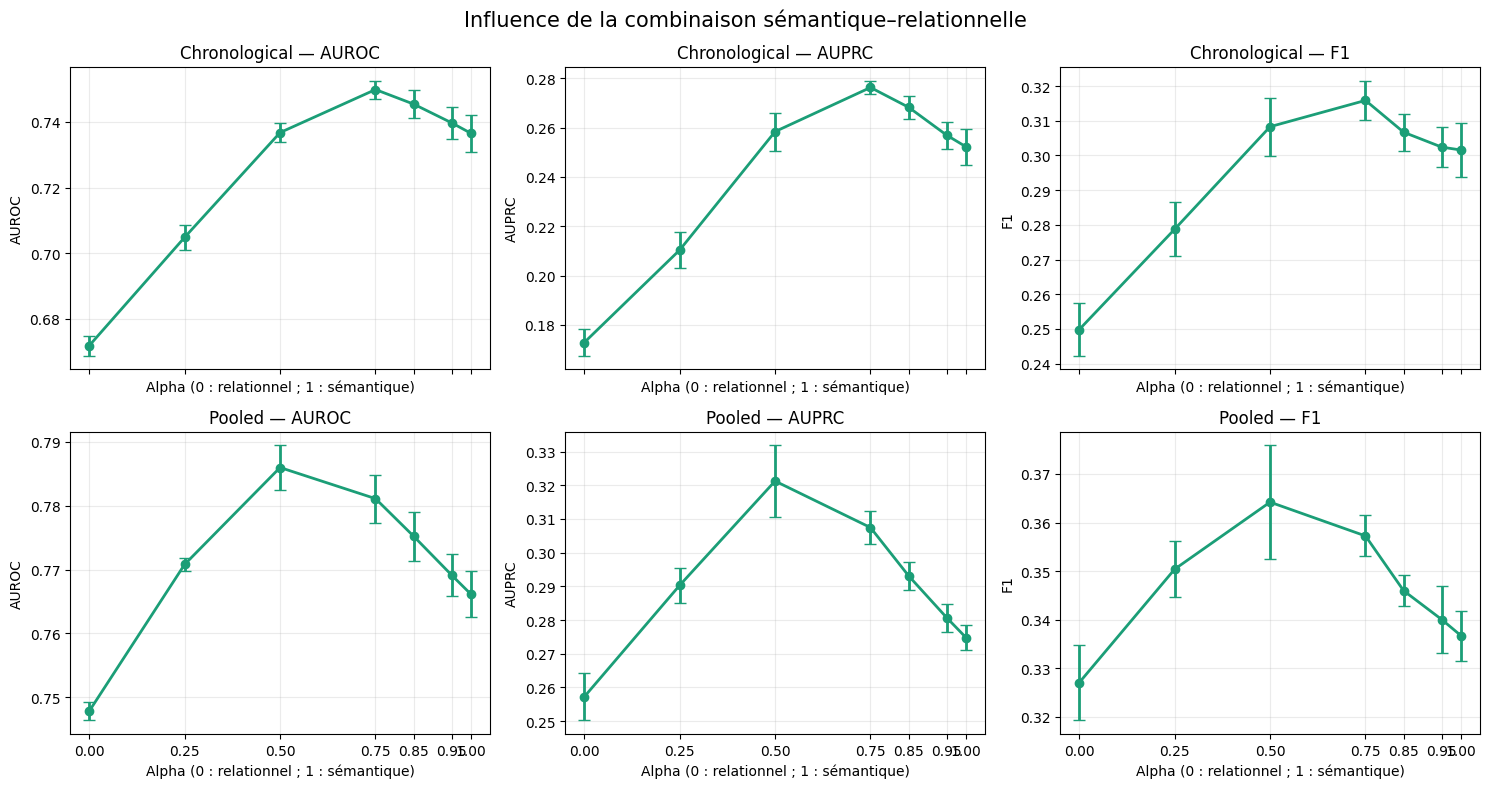

In [3]:
figure, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for row_index, protocol in enumerate(PROTOCOLS):
    for column_index, (metric, metric_label) in enumerate(alpha_metrics.items()):
        axis = axes[row_index, column_index]
        means = [alpha_aggregated.loc[(protocol, alpha), (metric, "mean")] for alpha in ALPHAS]
        stds = [alpha_aggregated.loc[(protocol, alpha), (metric, "std")] for alpha in ALPHAS]
        axis.errorbar(ALPHAS, means, yerr=stds, marker="o", capsize=4, linewidth=2, color="#1b9e77")
        axis.set_title(f"{protocol_label(protocol)} — {metric_label}")
        axis.set_xlabel("Alpha (0 : relationnel ; 1 : sémantique)")
        axis.set_ylabel(metric_label)
        axis.set_xticks(ALPHAS)
        axis.grid(alpha=0.25)
figure.suptitle("Influence de la combinaison sémantique–relationnelle", fontsize=15)
figure.tight_layout()
plt.show()

### Interprétation de l'ablation

- **Les deux branches isolées sont moins performantes que leur meilleure fusion.** En pooled, l'AUPRC passe de 0,257 (`alpha = 0`) et 0,275 (`alpha = 1`) à 0,321 (`alpha = 0.5`). En chronological, elle passe de 0,173 et 0,252 à 0,276 (`alpha = 0.75`).
- La branche sémantique est plus discriminante que la branche relationnelle lorsqu'elles sont utilisées seules. La fusion sélectionnée sur validation apporte un gain de 0,046 en pooled et de 0,006 en chronological par rapport à `alpha = 1`.
- L'AUPRC de validation sélectionne `alpha = 0.5` dans les deux protocoles. Cette valeur maximise également l'AUPRC de test en pooled. En chronological, `alpha = 0.75` atteint la meilleure AUPRC de test, mais constitue une analyse de sensibilité et non une configuration sélectionnée sur validation.
- Le meilleur F1 est obtenu avec `alpha = 0.5` en pooled et `alpha = 0.75` en chronological.

## Chargement et vérification des résultats

In [4]:
def result_path(model: str, protocol: str, ratio: float) -> Path:
    ratio_name = f"{ratio:g}"
    if protocol == "chronological_30_llm":
        base = OUTPUTS_DIR / "cpu_llm_chronological_30"
        if model == "lognet":
            return base / "lognet" / protocol / f"ratio_{ratio_name}" / "summary_by_seed.csv"
        if ratio == 0.1:
            return (
                base / "serag" / protocol / "ratio_0.1"
                / "alpha_0.5" / "summary_by_seed.csv"
            )
        return (
            base / "serag" / "alpha_0.5" / protocol
            / f"ratio_{ratio_name}" / "summary_by_seed.csv"
        )

    if model == "lognet":
        return (
            OUTPUTS_DIR / "cpu_llm_lognet_auprc" / protocol
            / f"ratio_{ratio_name}" / "summary_by_seed.csv"
        )
    if ratio == 0.1:
        return (
            OUTPUTS_DIR / "cpu_llm_alpha_sweep" / protocol / "ratio_0.1"
            / "alpha_0.5" / "summary_by_seed.csv"
        )

    base = OUTPUTS_DIR / "cpu_llm_ratio_sweep" / model
    if model == "serag":
        legacy_base = OUTPUTS_DIR / "cpu_llm_ratio_sweep" / "serad_kg"
        if not base.is_dir() and legacy_base.is_dir():
            base = legacy_base
        base = base / "alpha_0.5"
    return base / protocol / f"ratio_{ratio_name}" / "summary_by_seed.csv"


frames = []
for model in MODELS:
    for protocol in PROTOCOLS:
        for ratio in RATIOS:
            path = result_path(model, protocol, ratio)
            if not path.is_file():
                raise FileNotFoundError(path)
            frame = pd.read_csv(path)
            frame["model"] = model
            frame["protocol"] = protocol
            frame["ratio"] = ratio
            frames.append(frame)

results = pd.concat(frames, ignore_index=True)

completeness = (
    results.groupby(["protocol", "model", "ratio"], as_index=False)
    .agg(n_seeds=("seed", "nunique"), n_ok=("status", lambda values: values.eq("ok").sum()))
)
assert len(results) == len(PROTOCOLS) * len(MODELS) * len(RATIOS) * len(SEEDS)
assert completeness["n_seeds"].eq(len(SEEDS)).all()
assert completeness["n_ok"].eq(len(SEEDS)).all()
display(Markdown(f"**{len(results)} runs chargés ; toutes les configurations contiennent cinq seeds valides.**"))
display(completeness)

**100 runs chargés ; toutes les configurations contiennent cinq seeds valides.**

,protocol,model,ratio,n_seeds,n_ok
0,chronological_30_llm,lognet,0.010,5,5
1,chronological_30_llm,lognet,0.025,5,5
2,chronological_30_llm,lognet,0.050,5,5
3,chronological_30_llm,lognet,0.100,5,5
4,chronological_30_llm,lognet,0.200,5,5
5,chronological_30_llm,serag,0.010,5,5
6,chronological_30_llm,serag,0.025,5,5
7,chronological_30_llm,serag,0.050,5,5
8,chronological_30_llm,serag,0.100,5,5
9,chronological_30_llm,serag,0.200,5,5


In [5]:
METRICS = {
    "auc_test": "AUROC",
    "auprc_test": "AUPRC",
    "precision_test": "Précision",
    "recall_test": "Rappel",
    "f1_test": "F1",
}
MODEL_LABELS = {"lognet": "LoGNet", "serag": "SERAG"}
RATIO_LABELS = {0.01: "1 %", 0.025: "2,5 %", 0.05: "5 %", 0.1: "10 %", 0.2: "20 %"}

aggregated = (
    results.groupby(["protocol", "model", "ratio"])[list(METRICS)]
    .agg(["mean", "std"])
    .sort_index()
)


def french_number(value: float) -> str:
    return f"{value:.3f}".replace(".", ",")


def transposed_results_table(protocol: str) -> pd.DataFrame:
    rows = []
    index = []
    for model in MODELS:
        for metric, metric_label in METRICS.items():
            row = {}
            for ratio in RATIOS:
                values = aggregated.loc[(protocol, model, ratio), metric]
                row[RATIO_LABELS[ratio]] = (
                    f"{french_number(values['mean'])} ± {french_number(values['std'])}"
                )
            rows.append(row)
            index.append((MODEL_LABELS[model], metric_label))
    table = pd.DataFrame(
        rows,
        index=pd.MultiIndex.from_tuples(index, names=["Méthode", "Métrique"]),
    )
    return table[[RATIO_LABELS[ratio] for ratio in RATIOS]]

## 1. Protocole chronological

Les tableaux sont transposés par rapport à la présentation initiale : les ratios sont en colonnes.

In [6]:
chronological_table = transposed_results_table("chronological_30_llm")
display(chronological_table.style.set_caption("Résultats chronological — moyenne ± écart-type sur cinq seeds"))

## 2. Protocole pooled

In [7]:
pooled_table = transposed_results_table("pooled_30_llm")
display(pooled_table.style.set_caption("Résultats pooled — moyenne ± écart-type sur cinq seeds"))

## Évolution des performances avec le ratio d'anomalies

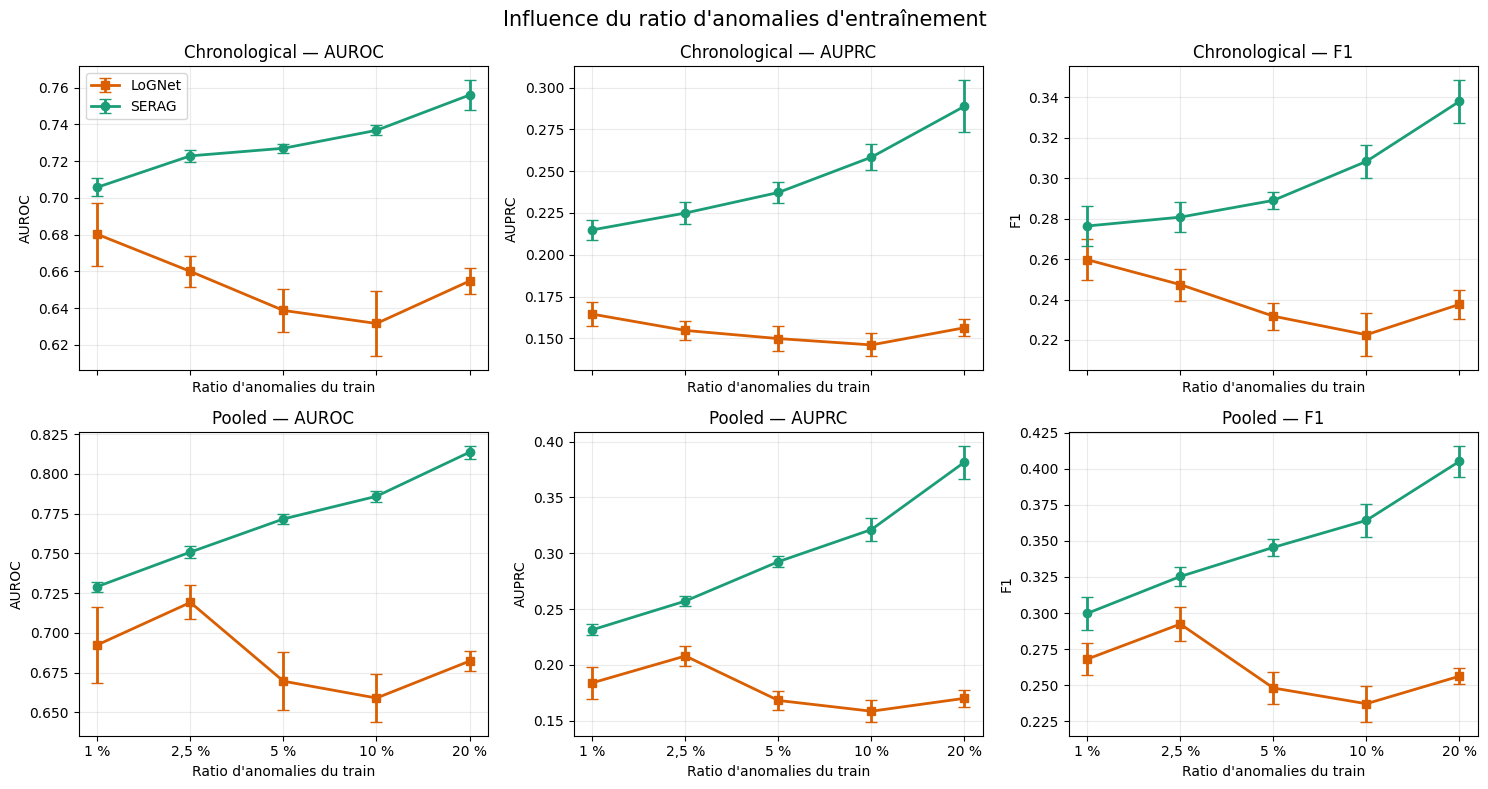

In [8]:
plot_metrics = {"auc_test": "AUROC", "auprc_test": "AUPRC", "f1_test": "F1"}
colors = {"lognet": "#d95f02", "serag": "#1b9e77"}
markers = {"lognet": "s", "serag": "o"}

figure, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for row_index, protocol in enumerate(PROTOCOLS):
    for column_index, (metric, metric_label) in enumerate(plot_metrics.items()):
        axis = axes[row_index, column_index]
        for model in MODELS:
            means = [aggregated.loc[(protocol, model, ratio), (metric, "mean")] for ratio in RATIOS]
            stds = [aggregated.loc[(protocol, model, ratio), (metric, "std")] for ratio in RATIOS]
            axis.errorbar(
                range(len(RATIOS)), means, yerr=stds,
                marker=markers[model], capsize=4, linewidth=2,
                color=colors[model], label=MODEL_LABELS[model],
            )
        axis.set_title(f"{protocol_label(protocol)} — {metric_label}")
        axis.set_xticks(range(len(RATIOS)), [RATIO_LABELS[ratio] for ratio in RATIOS])
        axis.set_xlabel("Ratio d'anomalies du train")
        axis.set_ylabel(metric_label)
        axis.grid(alpha=0.25)
        if row_index == 0 and column_index == 0:
            axis.legend()
figure.suptitle("Influence du ratio d'anomalies d'entraînement", fontsize=15)
figure.tight_layout()
plt.show()

## Sélection du ratio sur la validation

In [9]:
selection_rows = []
for protocol in PROTOCOLS:
    for model in MODELS:
        subset = results[(results["protocol"] == protocol) & (results["model"] == model)]
        validation_by_ratio = subset.groupby("ratio")["auprc_validation"].mean()
        selected_ratio = float(validation_by_ratio.idxmax())
        selected = subset[subset["ratio"] == selected_ratio]
        selection_rows.append(
            {
                "Protocole": protocol_label(protocol),
                "Méthode": MODEL_LABELS[model],
                "Ratio sélectionné": RATIO_LABELS[selected_ratio],
                "AUPRC validation": f"{french_number(selected.auprc_validation.mean())} ± {french_number(selected.auprc_validation.std(ddof=1))}",
                "AUROC test": f"{french_number(selected.auc_test.mean())} ± {french_number(selected.auc_test.std(ddof=1))}",
                "AUPRC test": f"{french_number(selected.auprc_test.mean())} ± {french_number(selected.auprc_test.std(ddof=1))}",
                "F1 test": f"{french_number(selected.f1_test.mean())} ± {french_number(selected.f1_test.std(ddof=1))}",
            }
        )

selection_table = pd.DataFrame(selection_rows)
display(selection_table.style.hide(axis="index").set_caption("Ratio choisi exclusivement sur l'AUPRC de validation"))

Protocole,Méthode,Ratio sélectionné,AUPRC validation,AUROC test,AUPRC test,F1 test
Chronological,LoGNet,1 %,"0,173 ± 0,008","0,680 ± 0,017","0,164 ± 0,007","0,260 ± 0,010"
Chronological,SERAG,20 %,"0,328 ± 0,012","0,756 ± 0,008","0,289 ± 0,016","0,338 ± 0,010"
Pooled,LoGNet,"2,5 %","0,232 ± 0,016","0,719 ± 0,011","0,208 ± 0,009","0,292 ± 0,012"
Pooled,SERAG,20 %,"0,408 ± 0,016","0,814 ± 0,004","0,382 ± 0,015","0,405 ± 0,011"


## Gains appariés de SERAG sur LoGNet

In [10]:
gain_rows = []
for protocol in PROTOCOLS:
    for ratio in RATIOS:
        serag = results[(results.protocol == protocol) & (results.model == "serag") & (results.ratio == ratio)].set_index("seed")
        lognet = results[(results.protocol == protocol) & (results.model == "lognet") & (results.ratio == ratio)].set_index("seed")
        row = {
            "Protocole": protocol_label(protocol),
            "Ratio": RATIO_LABELS[ratio],
        }
        for metric, label in (("auc_test", "Gain AUROC"), ("auprc_test", "Gain AUPRC"), ("f1_test", "Gain F1")):
            differences = serag[metric] - lognet[metric]
            interval = stats.t.interval(
                0.95, len(differences) - 1,
                loc=differences.mean(), scale=stats.sem(differences),
            )
            row[label] = (
                f"{french_number(differences.mean())} "
                f"[{french_number(interval[0])} ; {french_number(interval[1])}]"
            )
        gain_rows.append(row)

gain_table = pd.DataFrame(gain_rows)
display(gain_table.style.hide(axis="index").set_caption("Gain moyen [IC 95 %] de SERAG"))

Protocole,Ratio,Gain AUROC,Gain AUPRC,Gain F1
Chronological,1 %,"0,026 [0,006 ; 0,045]","0,050 [0,048 ; 0,053]","0,017 [0,001 ; 0,032]"
Chronological,"2,5 %","0,063 [0,051 ; 0,075]","0,070 [0,061 ; 0,080]","0,033 [0,016 ; 0,051]"
Chronological,5 %,"0,088 [0,072 ; 0,104]","0,087 [0,081 ; 0,094]","0,057 [0,045 ; 0,069]"
Chronological,10 %,"0,105 [0,082 ; 0,128]","0,112 [0,101 ; 0,123]","0,086 [0,066 ; 0,105]"
Chronological,20 %,"0,101 [0,090 ; 0,113]","0,133 [0,114 ; 0,151]","0,100 [0,081 ; 0,120]"
Pooled,1 %,"0,037 [0,007 ; 0,066]","0,047 [0,026 ; 0,069]","0,032 [0,007 ; 0,056]"
Pooled,"2,5 %","0,032 [0,017 ; 0,046]","0,049 [0,036 ; 0,062]","0,033 [0,013 ; 0,053]"
Pooled,5 %,"0,102 [0,080 ; 0,124]","0,124 [0,114 ; 0,134]","0,097 [0,080 ; 0,114]"
Pooled,10 %,"0,127 [0,111 ; 0,143]","0,163 [0,153 ; 0,172]","0,127 [0,113 ; 0,141]"
Pooled,20 %,"0,131 [0,127 ; 0,136]","0,211 [0,203 ; 0,220]","0,149 [0,137 ; 0,161]"


## Conclusions

- **SERAG surpasse LoGNet pour chaque ratio, dans les deux protocoles et sur les cinq seeds.**
- SERAG progresse régulièrement quand le nombre d'anomalies d'entraînement augmente ; la validation sélectionne **20 %** pour pooled et chronological.
- LoGNet atteint sa meilleure AUPRC à **2,5 %** en pooled et à **1 %** en chronological.
- À 20 %, SERAG atteint environ **0,382 d'AUPRC et 0,405 de F1** en pooled, et **0,289 d'AUPRC et 0,338 de F1** en chronological.
- L'ablation d'alpha montre que **la fusion surpasse chacune des deux branches isolées**. La validation sélectionne `alpha = 0.5` dans les deux protocoles ; `alpha = 0.75` obtient la meilleure AUPRC de test en chronological, mais n'est pas sélectionné sur validation.
- La comparaison correspond à SERAG complet contre la réimplémentation adaptée de LoGNet. SERAG utilise une BCE équilibrée, LoGNet une BCE standard, et les deux sélectionnent désormais leurs checkpoints sur l'AUPRC de validation.